<a href="https://colab.research.google.com/github/desireesosa/SimulacionII/blob/main/MovimientoBrownianoconDeriva.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<h1> Movimiento Browniano con Deriva </h1>

El movimiento browniano con deriva (o Brownian motion with drift) es un proceso estocástico continuo que extiende el movimiento browniano estándar al añadirle una tendencia o velocidad media determinista (deriva).

*Formula*

$$ X_t = \mu t + \sigma B_t, \quad t \geq 0, \sigma > 0, \mu \in \mathbb{R} $$

**Media**

$$ E[X_t] = \mu t + \sigma E[B_t] = \mu t $$

**Covarianza**

$X_t - E[X_t] = \sigma B_t$, entonces

$$ \text{cov}(X_t, X_s) = E[(\sigma B_t)(\sigma B_s)] = \sigma^2 E[B_t B_s] = \sigma^2 \min(t, s) $$

Comprobación: $\text{Var}(X_t) = \sigma^2 t$, es decir $X_t \sim N(\mu t, \sigma^2 t)$. La deriva solo mueve la media; la covarianza es la del MB escalada por $\sigma^2$.



**Problema:**
Considere un Movimiento Browniano con parámetros de deriva $\mu = 0.6$ y varianza $\sigma^2 = 0.25$ ($\sigma = 0.5$), definido por la ecuación:

$$X_t = 0.6t + 0.5 B_t$$

Encuentre la probabilidad de que el proceso $X_t$ tome valores en el intervalo $[1, 3]$ al tiempo $t = 4$, es decir:

$$P(1 < X_4 < 3)$$

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

In [ ]:
mu = 0.6 # Deriva
sigma2 = 0.25 # Varianza
sigma = np.sqrt(sigma2) # Desviación estándar (0.5)
T = 4.0 # Tiempo final t = 4
N_pasos = 400 # Pasos de discretización temporal
N_sim = 100000 # Número de simulaciones (caminatas N)

In [ ]:
media_teorica = mu * T
var_teorica = sigma2 * T
std_teorica = np.sqrt(var_teorica)
prob_teorica = norm.cdf(3, loc=media_teorica, scale=std_teorica) - norm.cdf(1, loc=media_teorica, scale=std_teorica)

print(f"--- RESULTADO TEÓRICO ---")
print(f"X_4 ~ N(media={media_teorica:.2f}, var={var_teorica:.2f})")
print(f"P(1 < X_4 < 3) Teórica = {prob_teorica:.4f}\n")

--- RESULTADO TEÓRICO ---
X_4 ~ N(media=2.40, var=1.00)
P(1 < X_4 < 3) Teórica = 0.6450



***Simulación por MonteCarlo***

In [ ]:
dt = T / N_pasos
t = np.linspace(0, T, N_pasos + 1)

dW = np.random.normal(loc=0.0, scale=np.sqrt(dt), size=(N_sim, N_pasos))

B = np.zeros((N_sim, N_pasos + 1))
B[:, 1:] = np.cumsum(dW, axis=1)

# Proceso X_t = mu * t + sigma * B_t
X = mu * t + sigma * B

X_4 = X[:, -1]

M = np.sum((X_4 >= 1) & (X_4 <= 3))
prob_empirica = M / N_sim

print(f"--- RESULTADO POR SIMULACIÓN (MONTE CARLO) ---")
print(f"Total caminatas (N) = {N_sim}")
print(f"Caminatas en [1, 3] (M) = {M}")
print(f"P_estimada (M / N) = {prob_empirica:.4f}")

--- RESULTADO POR SIMULACIÓN (MONTE CARLO) ---
Total caminatas (N) = 100000
Caminatas en [1, 3] (M) = 64298
P_estimada (M / N) = 0.6430


***Visualización***

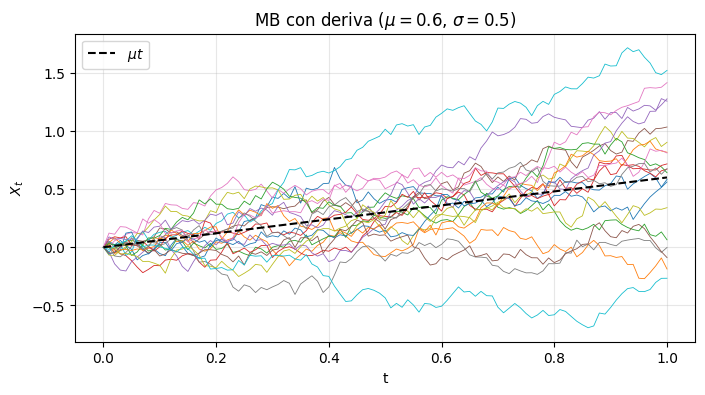

In [7]:
import numpy as np
import matplotlib.pyplot as plt

# Definir parámetros directamente para que la celda sea autocontenida
mu = 0.6
sigma = 0.5

def brown(T, N):
    dt = T / N
    dW = np.random.normal(0, np.sqrt(dt), N)
    return np.insert(np.cumsum(dW), 0, 0)

def deriva(mu, sigma, T, N):
    t = np.linspace(0, T, N + 1)
    X = mu * t + sigma * brown(T, N)
    return t, X

def trayectorias_deriva(n, mu, sigma, T=1, N=100):
    plt.figure(figsize=(8, 4))
    for _ in range(n):
        t, X = deriva(mu, sigma, T, N)
        plt.plot(t, X, lw=0.6)

    plt.plot(t, mu * t, 'k--', lw=1.5, label=r'$\mu t$')
    plt.title(rf'MB con deriva ($\mu={mu}$, $\sigma={sigma}$)')
    plt.xlabel('t')
    plt.ylabel('$X_t$')
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()

trayectorias_deriva(20, mu, sigma)